# Notebook 3 — Correlation Does Not Equal Causation

Strong correlations that are *not* what they look like — plus how the way data is collected changes the conclusion.

**What you will learn**
1. Why correlation alone cannot prove causation
2. **Confounding variables** and how to control for them (partial correlation)
3. **Observational vs experimental** data
4. Common patterns that create **spurious correlations**

## Setup
Run this cell first (and again after restarting the kernel). It imports the libraries we need and loads
`cafe_daily.csv`, which must sit in the same folder as this notebook.

- **pandas / numpy** – tables and numerical work
- **matplotlib / seaborn** – plotting
- **scipy.stats** – correlation and regression helpers

`cafe.head()` shows the first five rows so you can check the data loaded correctly.
See `data_dictionary.md` for what every column means.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

cafe = pd.read_csv("cafe_daily.csv", parse_dates=["date"])
cafe.head()

,date,day_of_week,is_weekend,temperature_c,iced_drink_sales,hot_drink_sales,cold_brew_sales,salad_sales,foot_traffic,barista_shoe_size,social_followers,promo_active,discount_pct,daily_revenue,daily_profit,pastry_demand
0,2024-01-01,Monday,0,2.0,30,168,11,8,229,41.5,499,1,15,817.78,850.41,70
1,2024-01-02,Tuesday,0,-0.2,25,191,7,14,216,43.0,503,0,35,881.36,560.69,57
2,2024-01-03,Wednesday,0,2.6,30,188,1,18,259,39.0,512,0,20,939.55,840.85,76
3,2024-01-04,Thursday,0,2.9,36,176,12,16,209,45.0,519,0,25,1031.60,780.45,60
4,2024-01-05,Friday,0,-1.8,13,176,2,0,218,42.5,520,1,15,795.42,857.18,65


## Part 1 — Correlation vs Causation

**Causation** means changing $x$ *produces* a change in $y$. **Correlation** only means $x$ and $y$ move together.
A strong correlation can arise from several situations:

| Explanation | Diagram |
|---|---|
| $x$ causes $y$ | $x \rightarrow y$ |
| $y$ causes $x$ (reverse causation) | $y \rightarrow x$ |
| a third variable $z$ causes both (confounding) | $x \leftarrow z \rightarrow y$ |
| coincidence / shared trend | no real link |

**Where:**

| Symbol | Meaning |
|---|---|
| $x$ | the first variable we observe (e.g. cold-brew sales) |
| $y$ | the second variable we observe (e.g. salad sales) |
| $z$ | a **third** variable that may affect both (e.g. temperature) |
| $\rightarrow$ | “causes” / “influences” — the arrow points from cause to effect |


Below, cold-brew and salad sales are strongly correlated. Does selling cold brew make people buy salad?

r(cold brew, salad) = +0.868


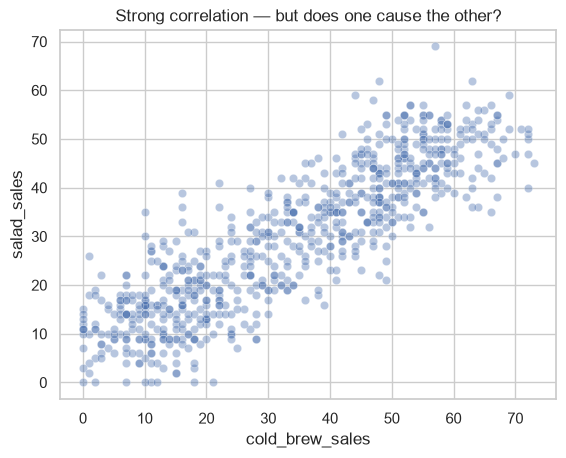

In [2]:
r,_ = stats.pearsonr(cafe['cold_brew_sales'], cafe['salad_sales'])
print(f'r(cold brew, salad) = {r:+.3f}')
sns.scatterplot(data=cafe, x='cold_brew_sales', y='salad_sales', alpha=.4)
plt.title('Strong correlation — but does one cause the other?'); plt.show()

$r \approx 0.87$ — a strong positive correlation. It is tempting to say "promote cold brew to sell more salad",
but nothing in this number tells us *why* they move together.

## Part 2 — Confounding Variables

A **confounder** is a third variable $z$ that influences **both** $x$ and $y$, creating a correlation between them
even when neither affects the other:

$$\text{cold brew} \;\leftarrow\; \text{temperature} \;\rightarrow\; \text{salad}$$

**Where:**

| Symbol | Meaning |
|---|---|
| $\text{temperature}$ | the **confounder** ($z$) — it drives both other variables |
| $\text{cold brew},\ \text{salad}$ | the two outcomes ($x$ and $y$) that look related |
| $\leftarrow,\ \rightarrow$ | “influences” — temperature affects each one; there is **no** arrow between cold brew and salad |


Colouring each point by temperature reveals the hidden driver: hot days (red) sit top-right, cold days (blue) bottom-left.

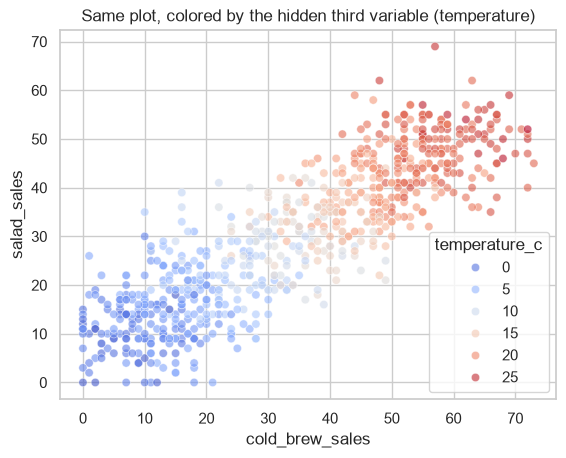

In [3]:
sns.scatterplot(data=cafe, x='cold_brew_sales', y='salad_sales',
                hue='temperature_c', palette='coolwarm', alpha=.6)
plt.title('Same plot, colored by the hidden third variable (temperature)'); plt.show()

### Controlling for the confounder — partial correlation

To ask "is there a link *after* accounting for temperature?" we:

1. Regress each variable on temperature with a straight line: $\hat{x}_i = a + b\,z_i$
2. Keep the **residuals** — what temperature cannot explain: $e_{x,i} = x_i - \hat{x}_i$ (and likewise $e_{y,i}$)
3. Correlate the residuals: $r_{xy\cdot z} = r(e_x, e_y)$

Equivalently, from the three pairwise correlations:

$$r_{xy\cdot z} = \frac{r_{xy} - r_{xz}\,r_{yz}}{\sqrt{(1-r_{xz}^2)(1-r_{yz}^2)}}$$

**Where:**

| Symbol | Meaning |
|---|---|
| $x,\ y$ | the two variables we want to compare (cold-brew and salad sales) |
| $z$ | the confounder we control for (temperature) |
| $z_i$ | the temperature on day $i$ |
| $\hat{x}_i$ | the value of $x$ **predicted** from temperature alone on day $i$ (the hat ^ means “predicted”) |
| $a,\ b$ | the intercept and slope of the straight line fitted between $z$ and $x$ |
| $e_{x,i},\ e_{y,i}$ | the **residuals** — the part of $x$ (or $y$) on day $i$ that temperature does *not* explain |
| $r(e_x, e_y)$ | the ordinary Pearson correlation of the two sets of residuals |
| $r_{xy\cdot z}$ | the **partial correlation** of $x$ and $y$ controlling for $z$ (read “r x-y given z”) |
| $r_{xy}$ | the ordinary correlation between $x$ and $y$ |
| $r_{xz},\ r_{yz}$ | the correlations of $x$ with $z$ and of $y$ with $z$ |


The `residuals()` helper below does steps 1–2 using `stats.linregress`.

In [4]:
# Partial correlation: remove temperature's influence from both, then correlate residuals
def residuals(y, x):
    s = stats.linregress(x, y)
    return y - (s.slope * x + s.intercept)
rb = residuals(cafe['cold_brew_sales'], cafe['temperature_c'])
rs = residuals(cafe['salad_sales'],     cafe['temperature_c'])
print(f'partial r (controlling for temperature) = {np.corrcoef(rb, rs)[0,1]:+.3f}')

partial r (controlling for temperature) = -0.016


The partial correlation is about **−0.02 ≈ 0**. Once temperature is accounted for, cold brew and salad have no
relationship at all. The original $r \approx 0.87$ came entirely from the confounder.

## Part 3 — Observational and Experimental Data

- **Observational data:** we simply record what happened. We do not control who/what gets the "treatment",
  so confounders can sneak in.
- **Experimental data:** we *randomly assign* the treatment. Randomisation makes the treatment independent of
  every other factor (on average), so the difference in outcomes reflects the treatment itself.

The estimate we compare in both cases is the difference in average revenue:

$$\text{effect} = \bar{y}_{\text{promo}} - \bar{y}_{\text{no promo}}$$

**Where:**

| Symbol | Meaning |
|---|---|
| $\text{effect}$ | the estimated increase in daily revenue caused by running a promo (€) |
| $\bar{y}_{\text{promo}}$ | the average daily revenue on days **with** a promo |
| $\bar{y}_{\text{no promo}}$ | the average daily revenue on days **without** a promo |


**Observational:** the café chose when to run promos, and mostly picked weekends — which are busy anyway.
So `promo_active` is correlated with `is_weekend`, and the weekend boost gets wrongly credited to the promo.

In [5]:
# Observational (confounded): promos cluster on weekends
print('corr(promo, weekend) =', round(cafe['promo_active'].corr(cafe['is_weekend']),3))
gap = (cafe[cafe.promo_active==1].daily_revenue.mean()
       - cafe[cafe.promo_active==0].daily_revenue.mean())
print(f'naive promo revenue gap = €{gap:.0f}  (overstated)')

corr(promo, weekend) = 0.505
naive promo revenue gap = €74  (overstated)


Promo and weekend are correlated (≈ 0.50), and the naive gap is about **€74** — but part of that is just the weekend effect.

**Experimental:** in `cafe_promo_experiment.csv` the promo was assigned at random (like a coin flip),
so it is unrelated to whether the day is a weekend.

In [6]:
# Experimental: promo assigned at random, independent of weekend
exp = pd.read_csv('cafe_promo_experiment.csv')
print('corr(promo, weekend) =', round(exp['promo_active'].corr(exp['is_weekend']),3))
gap = (exp[exp.promo_active==1].daily_revenue.mean()
       - exp[exp.promo_active==0].daily_revenue.mean())
print(f'experimental promo effect = €{gap:.0f}  (trustworthy)')

corr(promo, weekend) = 0.038
experimental promo effect = €48  (trustworthy)


Now promo and weekend are essentially uncorrelated (≈ 0.04), and the effect is about **€48** — close to the
true effect of €40 built into the data. Randomisation removed the confounder, so this estimate is trustworthy.

> The observational estimate (~€74) overstated the promo's value by roughly 50 %.

## Part 4 — Common Patterns Producing Spurious Correlations

A **spurious correlation** is a correlation that does not reflect a real, direct relationship. Three classic causes:

1. **Shared time trend** — two things that both grow (or shrink) over time will correlate, even if unrelated.
2. **Subgroup effect (Simpson's paradox)** — combining groups can hide or even reverse the relationship within each group.
3. **Data mining / coincidence** — test enough pairs of variables and some will correlate by pure chance.
   If you test $k$ unrelated pairs at significance level $\alpha$, you expect about $k \times \alpha$ false
   "discoveries" (e.g. 100 tests × 0.05 = 5). Always ask whether a relationship makes sense.

   - $k$ — the number of variable pairs you test
   - $\alpha$ — the significance level: the chance of a false alarm you accept for each test (usually 0.05 = 5 %)
   - $k \times \alpha$ — the expected number of correlations that look “significant” purely by chance

### (1) Shared time trend

Followers and revenue both increase steadily over the two years. To check whether they are related *beyond*
that trend, we **detrend** each series: fit a line against time $t$ and remove the slope,

$$x_t^{\text{detrended}} = x_t - \hat{\beta}_1\, t$$

**Where:**

| Symbol | Meaning |
|---|---|
| $t$ | time — the day number (0, 1, 2, …, 730) |
| $x_t$ | the value of the series (followers or revenue) on day $t$ |
| $\hat{\beta}_1$ | the slope of the straight line fitted between the series and time — the average growth per day |
| $\hat{\beta}_1\, t$ | the part of the value explained by the steady time trend |
| $x_t^{\text{detrended}}$ | what is left after removing the trend — the day-to-day ups and downs |


then correlate what remains.

In [7]:
# (1) Shared trend over time: revenue and followers both grow -> spurious r
r,_ = stats.pearsonr(cafe['social_followers'], cafe['daily_revenue'])
print(f'r(followers, revenue) raw        = {r:+.3f}')
t = np.arange(len(cafe))
fol = cafe['social_followers'] - (stats.linregress(t, cafe['social_followers']).slope * t)
rev = cafe['daily_revenue']    - (stats.linregress(t, cafe['daily_revenue']).slope * t)
print(f'r after removing the time trend  = {np.corrcoef(fol, rev)[0,1]:+.3f}')

r(followers, revenue) raw        = +0.724
r after removing the time trend  = -0.131


Raw $r \approx 0.72$ looks strong, but after removing the time trend it drops to about **−0.13** — essentially
no relationship. Both series were just growing over time.

### (2) Subgroup effect — Simpson's paradox

`cafe_two_stores.csv` has two locations. We compare the **pooled** correlation (both stores together)
with the correlation **within** each store.

pooled r            = -0.777
within Downtown     = +0.757
within Suburb       = +0.785


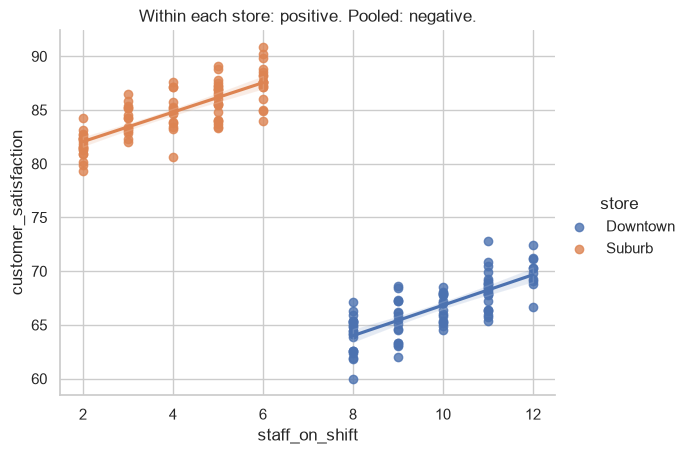

In [8]:
# (2) Subgroup effect (Simpson's paradox)
stores = pd.read_csv('cafe_two_stores.csv')
pooled = stores['staff_on_shift'].corr(stores['customer_satisfaction'])
print(f'pooled r            = {pooled:+.3f}')
for name, g in stores.groupby('store'):
    print(f'within {name:<8}     = {g.staff_on_shift.corr(g.customer_satisfaction):+.3f}')
sns.lmplot(data=stores, x='staff_on_shift', y='customer_satisfaction',
           hue='store', height=4.5, aspect=1.3)
plt.title('Within each store: positive. Pooled: negative.'); plt.show()

- **Pooled:** $r \approx -0.78$ → "more staff, *lower* satisfaction"?!
- **Within each store:** $r \approx +0.76$ (Downtown) and $+0.78$ (Suburb) → more staff, *higher* satisfaction.

The store is a confounder: Downtown is busy, so it has **more staff** but a **lower baseline** satisfaction.
Mixing the two groups creates a negative trend that is the opposite of what happens inside each store.
Always check whether your data contains meaningful subgroups.

### Key takeaways
- Correlation shows that variables move together, not **why**.
- Look for **confounders**; partial correlation can control for a measured one.
- **Randomised experiments** are the most reliable way to estimate a causal effect.
- Watch for **shared trends**, **subgroups (Simpson's paradox)** and **coincidences from data mining**.